In [6]:
import pandas as pd 
from pathlib import Path 

fichier = Path("../data/raw/Online Retail.xlsx")

df=pd.read_excel(fichier)

print("Dimensions :", df.shape)
print("\nvaleurs manquantes :")
print(df.isna().sum())
print("nTypes de données :")
df.info()

Dimensions : (541909, 8)

valeurs manquantes :
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64
nTypes de données :
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [7]:
print(df)

       InvoiceNo StockCode                          Description  Quantity  \
0         536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1         536365     71053                  WHITE METAL LANTERN         6   
2         536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3         536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4         536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   
...          ...       ...                                  ...       ...   
541904    581587     22613          PACK OF 20 SPACEBOY NAPKINS        12   
541905    581587     22899         CHILDREN'S APRON DOLLY GIRL          6   
541906    581587     23254        CHILDRENS CUTLERY DOLLY GIRL          4   
541907    581587     23255      CHILDRENS CUTLERY CIRCUS PARADE         4   
541908    581587     22138        BAKING SET 9 PIECE RETROSPOT          3   

               InvoiceDate  UnitPrice  CustomerID         Country  
0      

In [8]:
# Aperçu des données
print(df.head())

# Quantités négatives (retours) et prix à zéro
print("Quantités négatives :", (df["Quantity"] < 0).sum())
print("Prix <= 0 :", (df["UnitPrice"] <= 0).sum())

# Doublons
print("Doublons :", df.duplicated().sum())

  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

          InvoiceDate  UnitPrice  CustomerID         Country  
0 2010-12-01 08:26:00       2.55     17850.0  United Kingdom  
1 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
2 2010-12-01 08:26:00       2.75     17850.0  United Kingdom  
3 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
4 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
Quantités négatives : 10624
Prix <= 0 : 2517
Doublons : 5268


In [9]:
# 1. Tri des valeurs manquantes et comptage des doublons
print("Valeurs manquantes par colonne :")
print(df.isna().sum().sort_values(ascending=False))

print("\nNombre de doublons exacts :", df.duplicated().sum())

# 2. Identification des anomalies commerciales
# Les annulations sont repérables grâce à la lettre 'C' au début du numéro de facture
annulations = df["InvoiceNo"].astype(str).str.startswith("C")
print("\nFactures d'annulation (commençant par 'C') :", annulations.sum())

# Vérification des quantités et prix incohérents (négatifs ou nuls)
print("Lignes avec Quantité <= 0 :", (df["Quantity"] <= 0).sum())
print("Lignes avec Prix unitaire <= 0 :", (df["UnitPrice"] <= 0).sum())

Valeurs manquantes par colonne :
CustomerID     135080
Description      1454
StockCode           0
InvoiceNo           0
Quantity            0
InvoiceDate         0
UnitPrice           0
Country             0
dtype: int64

Nombre de doublons exacts : 5268

Factures d'annulation (commençant par 'C') : 9288
Lignes avec Quantité <= 0 : 10624
Lignes avec Prix unitaire <= 0 : 2517


In [10]:
# 1. Création d'une copie de travail
df_clean = df.copy()

# 2. Nettoyage des espaces dans les textes et colonnes
df_clean.columns = df_clean.columns.str.strip()
df_clean["Description"] = df_clean["Description"].astype("string").str.strip()
df_clean["Country"] = df_clean["Country"].astype("string").str.strip()

# 3. Conversion de la date au bon format
df_clean["InvoiceDate"] = pd.to_datetime(df_clean["InvoiceDate"], errors="coerce")

# 4. Création de la colonne "LineTotal" (Quantité x Prix)
df_clean["LineTotal"] = df_clean["Quantity"] * df_clean["UnitPrice"]

# 5. Séparation des annulations et des ventes
mask_c = df_clean["InvoiceNo"].astype(str).str.startswith("C")
df_returns = df_clean[mask_c].copy()

# Filtrage strict pour les ventes (sans les C, Quantité > 0, Prix > 0, Date non nulle)
df_sales = df_clean[~mask_c].copy()
df_sales = df_sales[
    (df_sales["Quantity"] > 0) & 
    (df_sales["UnitPrice"] > 0) & 
    (df_sales["InvoiceDate"].notna())
].copy()

# 6. Exportation vers le dossier "processed"
df_sales.to_csv("../data/processed/ventes_nettoyees.csv", index=False, encoding="utf-8-sig")
df_returns.to_csv("../data/processed/retours_annulations.csv", index=False, encoding="utf-8-sig")

# 7. Vérification finale
print("Ventes (prêtes pour l'analyse) :", df_sales.shape)
print("Retours/annulations isolés :", df_returns.shape)

Ventes (prêtes pour l'analyse) : (530104, 9)
Retours/annulations isolés : (9288, 9)


In [11]:
# 5.1 Indicateurs globaux
ca_positif = df_sales["LineTotal"].sum()
factures = df_sales["InvoiceNo"].nunique()
clients = df_sales["CustomerID"].nunique()
produits = df_sales["StockCode"].nunique()
quantite = df_sales["Quantity"].sum()

print("--- INDICATEURS GLOBAUX ---")
print("CA positif :", round(ca_positif, 2))
print("Factures :", factures)
print("Clients identifiés :", clients)
print("Produits distincts :", produits)
print("Unités vendues :", quantite)

# 5.2 Top produits par montant
print("\n--- TOP 10 PRODUITS (par CA) ---")
top_montants = (
    df_sales.groupby("Description")["LineTotal"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)
print(top_montants)

# 5.3 Ventes par pays
print("\n--- TOP 10 PAYS (par CA) ---")
ventes_pays = (
    df_sales.groupby("Country")["LineTotal"]
    .sum()
    .sort_values(ascending=False)
)
print(ventes_pays.head(10))

--- INDICATEURS GLOBAUX ---
CA positif : 10666684.54
Factures : 19960
Clients identifiés : 4338
Produits distincts : 3922
Unités vendues : 5588376

--- TOP 10 PRODUITS (par CA) ---
Description
DOTCOM POSTAGE                        206248.77
REGENCY CAKESTAND 3 TIER              174484.74
PAPER CRAFT , LITTLE BIRDIE           168469.60
WHITE HANGING HEART T-LIGHT HOLDER    106292.77
PARTY BUNTING                          99504.33
JUMBO BAG RED RETROSPOT                94340.05
MEDIUM CERAMIC TOP STORAGE JAR         81700.92
Manual                                 78112.82
POSTAGE                                78101.88
RABBIT NIGHT LIGHT                     66964.99
Name: LineTotal, dtype: float64

--- TOP 10 PAYS (par CA) ---
Country
United Kingdom    9025222.084
Netherlands        285446.340
EIRE               283453.960
Germany            228867.140
France             209715.110
Australia          138521.310
Spain               61577.110
Switzerland         57089.900
Belgium          

In [13]:
!pip install matplotlib

     ---------------------------------------- 0.0/80.3 kB ? eta -:--:--
     ---------------------------------------- 0.0/80.3 kB ? eta -:--:--
     ----- ---------------------------------- 10.2/80.3 kB ? eta -:--:--
     --------- ---------------------------- 20.5/80.3 kB 131.3 kB/s eta 0:00:01
     -------------- ----------------------- 30.7/80.3 kB 163.8 kB/s eta 0:00:01
     ------------------------ ------------- 51.2/80.3 kB 219.0 kB/s eta 0:00:01
     -------------------------------------- 80.3/80.3 kB 299.2 kB/s eta 0:00:00
     ---------------------------------------- 0.0/142.6 kB ? eta -:--:--
     ----------------------------------- -- 133.1/142.6 kB 3.8 MB/s eta 0:00:01
     -------------------------------------- 142.6/142.6 kB 4.1 MB/s eta 0:00:00
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.3 MB 5.4 MB/s eta 0:00:02
   --- ------------------------------------ 0.8/9.3 MB 8.6 MB/s eta 0:00:01
   ----- 


[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: C:\Users\tarik\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


Matplotlib is building the font cache; this may take a moment.


--- VENTES MENSUELLES ---
YearMonth
2010-12     823746.140
2011-01     691364.560
2011-02     523631.890
2011-03     717639.360
2011-04     537808.621
2011-05     770536.020
2011-06     761739.900
2011-07     719221.191
2011-08     759138.380
2011-09    1058590.172
2011-10    1154979.300
2011-11    1509496.330
2011-12     638792.680
Name: LineTotal, dtype: float64


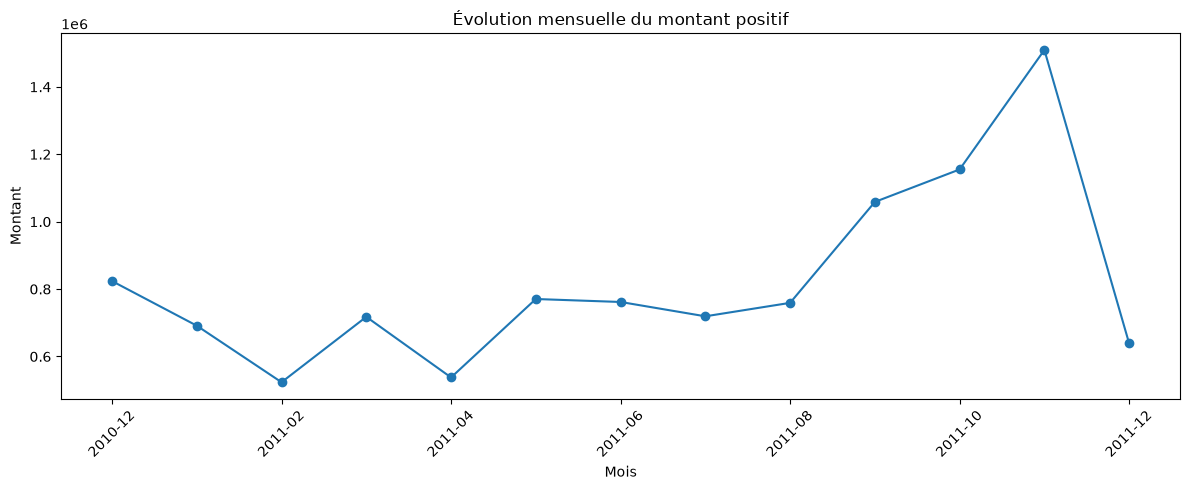

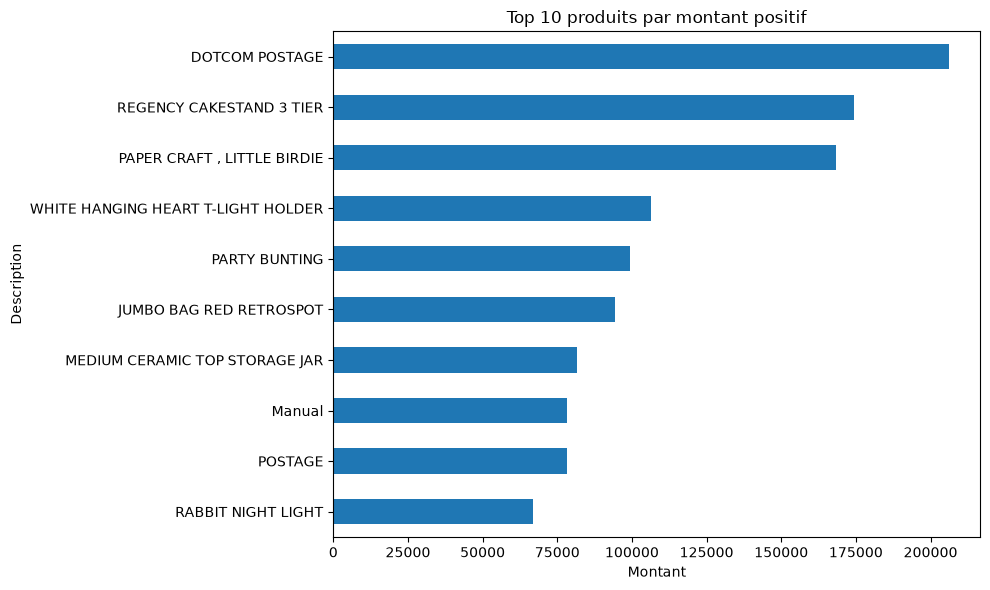

In [14]:
import matplotlib.pyplot as plt

# 5.3 (Suite) Calcul des ventes par mois
df_sales["YearMonth"] = df_sales["InvoiceDate"].dt.to_period("M").astype(str)
ventes_mensuelles = df_sales.groupby("YearMonth")["LineTotal"].sum().sort_index()

print("--- VENTES MENSUELLES ---")
print(ventes_mensuelles)

# 5.4 Graphique 1 : Évolution mensuelle du chiffre d'affaires
ventes_mensuelles.plot(kind="line", figsize=(12, 5), marker="o")
plt.title("Évolution mensuelle du montant positif")
plt.xlabel("Mois")
plt.ylabel("Montant")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 5.4 Graphique 2 : Top 10 produits par montant
top_montants.sort_values().plot(kind="barh", figsize=(10, 6))
plt.title("Top 10 produits par montant positif")
plt.xlabel("Montant")
plt.tight_layout()
plt.show()

In [15]:
# 6. Préparation des données pour RFM (uniquement les clients identifiés)
clients_df = df_sales.dropna(subset=["CustomerID"]).copy()

# On fixe une date de référence (le lendemain du dernier achat du dataset)
date_ref = clients_df["InvoiceDate"].max() + pd.Timedelta(days=1)

# Calcul des indicateurs R, F et M par client
rfm = clients_df.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda x: (date_ref - x.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("LineTotal", "sum")
)

print("--- APERÇU RFM BRUT ---")
print(rfm.head())

# 6.1 Création des scores de 1 à 4 (4 étant le meilleur)
# Pour la Récence, un nombre de jours petit est meilleur (d'où l'ordre 4, 3, 2, 1)
rfm["R_score"] = pd.qcut(rfm["Recency"].rank(method="first"), 4, labels=[4, 3, 2, 1]).astype(int)
rfm["F_score"] = pd.qcut(rfm["Frequency"].rank(method="first"), 4, labels=[1, 2, 3, 4]).astype(int)
rfm["M_score"] = pd.qcut(rfm["Monetary"].rank(method="first"), 4, labels=[1, 2, 3, 4]).astype(int)

# Concaténation pour obtenir le score RFM global (ex: "444")
rfm["RFM_score"] = rfm["R_score"].astype(str) + rfm["F_score"].astype(str) + rfm["M_score"].astype(str)

print("\n--- TOP 10 CLIENTS (par Montant) AVEC SCORES RFM ---")
print(rfm.sort_values("Monetary", ascending=False).head(10))

--- APERÇU RFM BRUT ---
            Recency  Frequency  Monetary
CustomerID                              
12346.0         326          1  77183.60
12347.0           2          7   4310.00
12348.0          75          4   1797.24
12349.0          19          1   1757.55
12350.0         310          1    334.40

--- TOP 10 CLIENTS (par Montant) AVEC SCORES RFM ---
            Recency  Frequency   Monetary  R_score  F_score  M_score RFM_score
CustomerID                                                                    
14646.0           2         73  280206.02        4        4        4       444
18102.0           1         60  259657.30        4        4        4       444
17450.0           8         46  194550.79        4        4        4       444
16446.0           1          2  168472.50        4        2        4       424
14911.0           1        201  143825.06        4        4        4       444
12415.0          24         21  124914.53        3        4        4       344
141

In [16]:
import sqlite3

# Création d'une base de données SQLite locale dans ton dossier processed
conn = sqlite3.connect('../data/processed/ecommerce_db.sqlite')

# Sauvegarde de ton DataFrame nettoyé sous forme de table SQL nommée "ventes"
df_sales.to_sql('ventes', conn, if_exists='replace', index=False)

# 7.1 Vérifier les données avec une requête SQL
query_check = """
SELECT * 
FROM ventes 
LIMIT 5;
"""
print("--- APERÇU DE LA TABLE SQL ---")
print(pd.read_sql_query(query_check, conn))

# 7.2 Montant positif total
query_ca = """
SELECT ROUND(SUM(LineTotal), 2) AS ca_positif 
FROM ventes;
"""
print("\n--- CA POSITIF TOTAL (SQL) ---")
print(pd.read_sql_query(query_ca, conn))

--- APERÇU DE LA TABLE SQL ---
  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

           InvoiceDate  UnitPrice  CustomerID         Country  LineTotal  \
0  2010-12-01 08:26:00       2.55     17850.0  United Kingdom      15.30   
1  2010-12-01 08:26:00       3.39     17850.0  United Kingdom      20.34   
2  2010-12-01 08:26:00       2.75     17850.0  United Kingdom      22.00   
3  2010-12-01 08:26:00       3.39     17850.0  United Kingdom      20.34   
4  2010-12-01 08:26:00       3.39     17850.0  United Kingdom      20.34   

  YearMonth  
0   2010-12  
1   2010-12  
2   2010-12  
3   2010-12  
4   2010-

In [17]:
# 7.3 Top 10 produits
query_top_produits = """
SELECT Description, ROUND(SUM(LineTotal), 2) AS montant
FROM ventes
GROUP BY Description
ORDER BY montant DESC
LIMIT 10;
"""
print("--- TOP 10 PRODUITS (SQL) ---")
print(pd.read_sql_query(query_top_produits, conn))

# 7.4 Ventes par pays (Top 10)
query_pays = """
SELECT Country, ROUND(SUM(LineTotal), 2) AS montant
FROM ventes
GROUP BY Country
ORDER BY montant DESC
LIMIT 10;
"""
print("\n--- VENTES PAR PAYS (SQL) ---")
print(pd.read_sql_query(query_pays, conn))

# 7.5 Ventes par mois (en utilisant strftime pour SQLite)
query_mois = """
SELECT strftime('%Y-%m', InvoiceDate) AS mois,
       ROUND(SUM(LineTotal), 2) AS montant
FROM ventes
GROUP BY mois
ORDER BY mois;
"""
print("\n--- VENTES PAR MOIS (SQL) ---")
print(pd.read_sql_query(query_mois, conn))

# 7.6 Meilleurs clients
query_clients = """
SELECT CustomerID,
       COUNT(DISTINCT InvoiceNo) AS nb_factures,
       ROUND(SUM(LineTotal), 2) AS montant
FROM ventes
WHERE CustomerID IS NOT NULL
GROUP BY CustomerID
ORDER BY montant DESC
LIMIT 20;
"""
print("\n--- MEILLEURS CLIENTS (SQL) ---")
print(pd.read_sql_query(query_clients, conn))

--- TOP 10 PRODUITS (SQL) ---
                          Description    montant
0                      DOTCOM POSTAGE  206248.77
1            REGENCY CAKESTAND 3 TIER  174484.74
2         PAPER CRAFT , LITTLE BIRDIE  168469.60
3  WHITE HANGING HEART T-LIGHT HOLDER  106292.77
4                       PARTY BUNTING   99504.33
5             JUMBO BAG RED RETROSPOT   94340.05
6      MEDIUM CERAMIC TOP STORAGE JAR   81700.92
7                              Manual   78112.82
8                             POSTAGE   78101.88
9                  RABBIT NIGHT LIGHT   66964.99

--- VENTES PAR PAYS (SQL) ---
          Country     montant
0  United Kingdom  9025222.08
1     Netherlands   285446.34
2            EIRE   283453.96
3         Germany   228867.14
4          France   209715.11
5       Australia   138521.31
6           Spain    61577.11
7     Switzerland    57089.90
8         Belgium    41196.34
9          Sweden    38378.33

--- VENTES PAR MOIS (SQL) ---
       mois     montant
0   2010-12   8